# 06 — Demo Klasifikasi

Uji coba model terbaik yang disimpan di notebook 04 (`models/best_model.joblib`) pada citra satuan, memakai `src/predict.py`. Fungsi `predict_image(path)` menjalankan preprocessing dan ekstraksi fitur yang **persis sama** dengan training, lalu mengembalikan label beserta 3 kandidat teratas.

Notebook ini tidak melatih atau memilih model apa pun; semua keputusan sudah dibekukan di notebook 03–04.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
t0 = time.time()

import json
from PIL import Image
from src.predict import predict_image, load_model, IMAGE_EXTS
pd.set_option("display.max_colwidth", 120)

FIG_DIR = config.FIGURES_DIR / "06_demo"
FIG_DIR.mkdir(parents=True, exist_ok=True)
model, meta = load_model(config.MODELS_DIR)
print(f"Model: {meta['scenario']} + SVM {meta['kernel']}, params {meta['params']}")
print(f"F1 makro CV {meta['cv_f1_macro_mean']} ± {meta['cv_f1_macro_std']}, F1 makro uji {meta['test_f1_macro']}")
print(f"{len(meta['feature_columns'])} fitur, IMG_SIZE {meta['IMG_SIZE']}, scikit-learn {meta['sklearn_version']}")

Model: S2 + SVM linear, params {'C': 100}
F1 makro CV 0.9799 ± 0.0114, F1 makro uji 1.0
12 fitur, IMG_SIZE 256, scikit-learn 1.9.1


**Tentang skor.** Skor kandidat berasal dari `decision_function` SVM. Karena `SVC` multikelas memakai skema *one-vs-one*, skor tiap kelas pada dasarnya adalah jumlah "suara" yang dimenangkan kelas itu dari 55 pasangan kelas, ditambah sedikit nilai keyakinan. Skor ini berguna untuk **mengurutkan** kandidat, tetapi **bukan probabilitas**: nilainya tidak berjumlah 1 dan tidak bisa dibaca sebagai "yakin sekian persen".

## 1. Demo pada citra uji

Satu foto uji per kelas. Foto-foto ini sudah dipakai untuk evaluasi akhir di notebook 04; di sini hanya ditampilkan ulang sebagai contoh cara kerja `predict_image`. Label hasil `predict_image` dicocokkan dengan prediksi notebook 04 (`results/test_predictions.csv`) untuk memastikan jalur prediksinya sama.

In [2]:
ref = pd.read_csv(config.RESULTS_DIR / "test_predictions.csv")
ref_col = f"pred_{meta['scenario']}_{meta['kernel']}"
demo = ref.groupby("label").head(1).set_index("label").loc[config.CLASSES].reset_index()

results = []
for _, r in demo.iterrows():
    res = predict_image(config.RAW_DIR / r["filename"])
    results.append({"file": r["filename"].split("/")[1], "label": r["label"], "prediksi": res["label"],
                    "sama dgn notebook 04": res["label"] == r[ref_col],
                    "top-3": ", ".join(f"{l} ({s:.2f})" for l, s in res["top"])})
results = pd.DataFrame(results)
results

,file,label,prediksi,sama dgn notebook 04,top-3
0,Angguran (10).jpg,Angguran,Angguran,True,"Angguran (10.32), Jahe Puger (9.33), Puger Galar (8.30)"
1,Ayam Puger (10).jpg,Ayam Puger,Ayam Puger,True,"Ayam Puger (10.31), Lumbon (8.32), Jahe Lumbon (7.32)"
2,Jahe Lumbon (13).jpg,Jahe Lumbon,Jahe Lumbon,True,"Jahe Lumbon (10.32), Madu Bronto (9.29), Jahe Srimpang (8.30)"
3,Jahe Puger (14).jpg,Jahe Puger,Jahe Puger,True,"Jahe Puger (10.32), Wit Lumbon (9.31), Jahe Lumbon (8.31)"
4,Jahe Srimpang (10).jpg,Jahe Srimpang,Jahe Srimpang,True,"Jahe Srimpang (10.33), Angguran (9.31), Wit Lumbon (8.31)"
5,Lumbon (1).jpg,Lumbon,Lumbon,True,"Lumbon (10.33), Ayam Puger (9.32), Jahe Lumbon (8.33)"
6,Madu Bronto (16).jpg,Madu Bronto,Madu Bronto,True,"Madu Bronto (10.32), Wit Lumbon (9.32), Lumbon (8.33)"
7,Pring Sedapur (10).jpg,Pring Sedapur,Pring Sedapur,True,"Pring Sedapur (10.32), Jahe Lumbon (9.33), Ayam Puger (8.32)"
8,Puger Galar (20).jpg,Puger Galar,Puger Galar,True,"Puger Galar (10.32), Lumbon (8.32), Wit Lumbon (8.31)"
9,Puger Telu Bal (1).jpg,Puger Telu Bal,Puger Telu Bal,True,"Puger Telu Bal (10.31), Lumbon (9.32), Jahe Lumbon (8.32)"


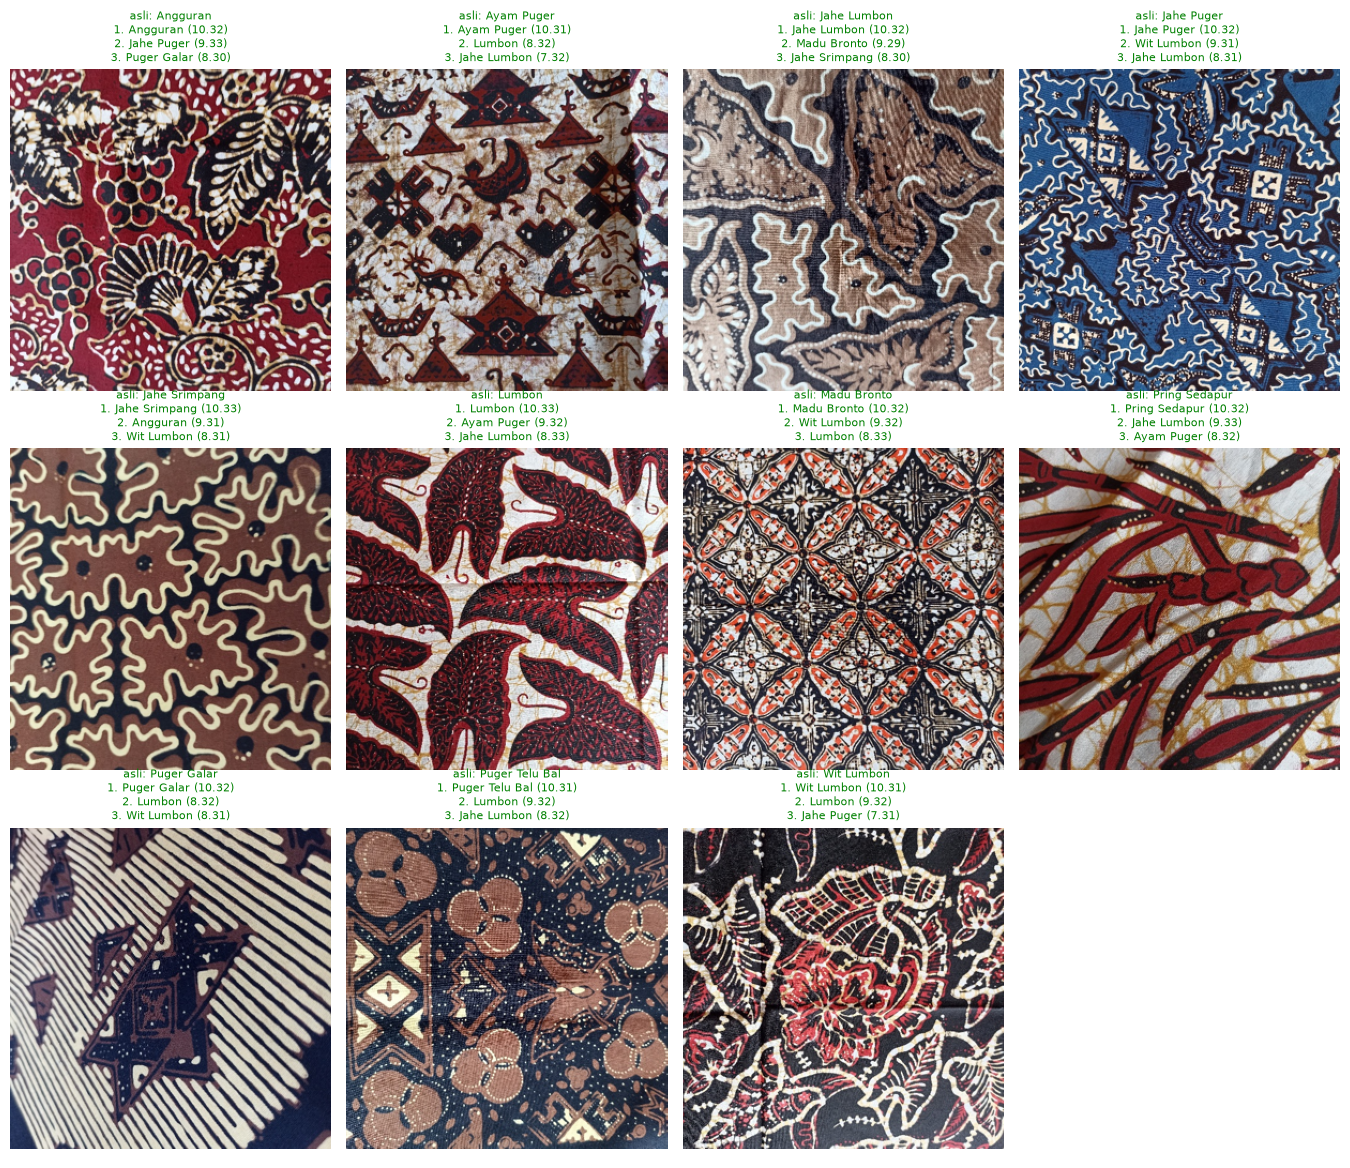

Benar: 11 dari 11; sama dengan notebook 04: 11 dari 11


In [3]:
def show_grid(files, titles, colors, path, ncols=4):
    nrows = int(np.ceil(len(files) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.9 * nrows))
    for ax in np.atleast_1d(axes).flat:
        ax.axis("off")
    for ax, f, t, c in zip(np.atleast_1d(axes).flat, files, titles, colors):
        im = Image.open(f).convert("RGB"); im.thumbnail((300, 300))
        ax.imshow(im); ax.set_title(t, fontsize=8, color=c)
    fig.tight_layout()
    fig.savefig(path, dpi=90)
    plt.show()

titles, colors = [], []
for (_, r), (_, d) in zip(results.iterrows(), demo.iterrows()):
    res = predict_image(config.RAW_DIR / d["filename"])
    top = "\n".join(f"{i + 1}. {l} ({s:.2f})" for i, (l, s) in enumerate(res["top"]))
    titles.append(f"asli: {r['label']}\n{top}")
    colors.append("green" if r["prediksi"] == r["label"] else "red")
show_grid([config.RAW_DIR / f for f in demo["filename"]], titles, colors, FIG_DIR / "demo_citra_uji.png")
print(f"Benar: {(results['prediksi'] == results['label']).sum()} dari {len(results)}; "
      f"sama dengan notebook 04: {results['sama dgn notebook 04'].sum()} dari {len(results)}")

## 2. Foto baru di `data/demo/`

Letakkan foto batik sendiri (`.jpg`, `.png`, dll.) di folder `data/demo/`, lalu jalankan ulang sel di bawah. Foto tidak perlu persegi atau berukuran 512 piksel: `predict_image` otomatis memotong bagian tengah menjadi persegi dan mengecilkannya ke 256×256.

Catatan penting: model dilatih dari foto kain-kain di satu rumah batik, dan pemeriksaan di notebook 04 menunjukkan foto uji berasal dari kain yang sama dengan foto latih. Foto dari kain lain, pencahayaan lain, atau jarak kamera yang berbeda bisa saja diklasifikasikan jauh lebih buruk daripada angka di data uji. Hasil di bagian ini adalah uji coba, bukan pengukuran akurasi.

In [ ]:
demo_files = sorted(f for f in config.DEMO_DIR.iterdir() if f.suffix.lower() in IMAGE_EXTS) if config.DEMO_DIR.is_dir() else []
if not demo_files:
    print(f"Belum ada foto di {config.DEMO_DIR.relative_to(config.ROOT)}. Tambahkan foto lalu jalankan ulang sel ini.")
else:
    new = [{"file": f.name, **predict_image(f)} for f in demo_files]
    for n in new:
        print(f"{n['file']}: {n['label']}  | " + ", ".join(f"{l} ({s:.2f})" for l, s in n["top"]))
    show_grid(demo_files,
              [f"{n['file']}\n" + "\n".join(f"{i + 1}. {l} ({s:.2f})" for i, (l, s) in enumerate(n["top"])) for n in new],
              ["black"] * len(new), FIG_DIR / "demo_foto_baru.png")

## 3. Lewat command line

Prediksi yang sama bisa dijalankan dari terminal, untuk satu file atau satu folder:

```bash
uv run python -m src.predict "data/raw/batik_banyumasan/Puger Galar/Puger Galar (1).jpg"
uv run python -m src.predict data/demo/
```

In [5]:
print(f"Waktu jalan notebook: {time.time() - t0:.0f} detik")

Waktu jalan notebook: 4 detik
